In [1]:
#%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import csv
import os

In [2]:
# Load csv
def load_multi_fidelity_csv_results(file_name):
    points_lf = []
    points_hf = []
    model_error = []
    training_time = []
    evaluation_time = []
    with open(file_name,mode='r') as file:
        reader = csv.reader(file)
        for row in reader:
            print(row)
            points_lf.append(int(row[0]))
            points_hf.append(int(row[1]))
            model_error.append(float(row[2]))
            training_time.append(float(row[3]))
            evaluation_time.append(float(row[4]))
    return points_lf, points_hf, model_error, training_time, evaluation_time

# Load csv
def load_single_fidelity_csv_results(file_name):
    points = []
    model_error = []
    training_time = []
    evaluation_time = []
    with open(file_name,mode='r') as file:
        reader = csv.reader(file)
        header = next(reader)
        for row in reader:
            points.append(int(row[0]))
            model_error.append(float(row[1]))
            training_time.append(float(row[2]))
            #evaluation_time.append(float(row[3]))
    return points, model_error, training_time, evaluation_time

In [3]:
# Function plotting

def plot_cokriging_data(
    points_lf,
    points_hf,
    output,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        plt.close()
        fig = plt.figure(name)
        ax = fig.add_subplot(projection="3d")
    ax.set_title(name)
    ax.set_xlabel("Samples LF")
    ax.set_ylabel("Samples HF")
    ax.set_zlabel(label)

    if log_output:
        output = np.log10(output)

    ax.scatter(
        points_lf,
        points_hf,
        output,
        color=color,
        label=label,
    )
def plot_single_fidelity_data(
    points,
    output,
    name="Cokriging Data",
    color="black",
    label="data",
    y_label = "RMSE",
    x_label = "Samples",
    log_output=False,
    ax=None,
):
    if ax == None:
        plt.close()
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

    if log_output==True:
        output = np.log10(output)

    ax.scatter(
        points,
        output,
        color=color,
        label=label,
    )
    
    return ax

def plot_cokriging_data_slice(
    points_lf,
    points_hf,
    output,
    fix_lf=True,
    fix_value=10,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        plt.close()
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    x_values = []
    y_values = []
    if fix_lf:
        ax.set_xlabel("Samples HF")
        for i, val in enumerate(points_lf):
            if val == fix_value:
                x_values.append(points_hf[i])
                y_values.append(output[i])
    else:
        ax.set_xlabel("Samples_LF")
        for i, val in enumerate(points_hf):
            if val == fix_value:
                x_values.append(points_lf[i])
                y_values.append(output[i])
    ax.set_ylabel(label)

    if log_output:
        y_values = np.log10(y_values)

    print(x_values)
    ax.scatter(
        x_values,
        y_values,
        color=color,
        label=label,
    )
    return ax


# Saves a figure as a PNG under plots/SFComp, relative to this notebook's folder
PLOT_DIR = os.path.join("plots", "SFComp")


def save_plot(ax, name, plot_dir=PLOT_DIR):
    os.makedirs(plot_dir, exist_ok=True)
    file_name = os.path.join(plot_dir, name.replace(" ", "_") + ".png")
    ax.figure.savefig(file_name, dpi=300, bbox_inches="tight")
    print("saved", file_name)


# 2D comparison

In [4]:
kriging2D_points,kriging2D_error,kriging2D_traintime,kriging2D_evaltime = load_single_fidelity_csv_results('Comparisons/kriging_model_comparison_2D.csv')
kan2D_points,kan2D_error,kan2D_traintime,kan2D_evaltime = load_single_fidelity_csv_results('Comparisons/kan_model_comparison_2D.csv')
mlp2D_points,mlp2D_error,mlp2D_traintime,mlp2D_evaltime = load_single_fidelity_csv_results('Comparisons/nn_model_comparison_2d.csv')

saved plots\SFComp\Error_Comparison_2D.png


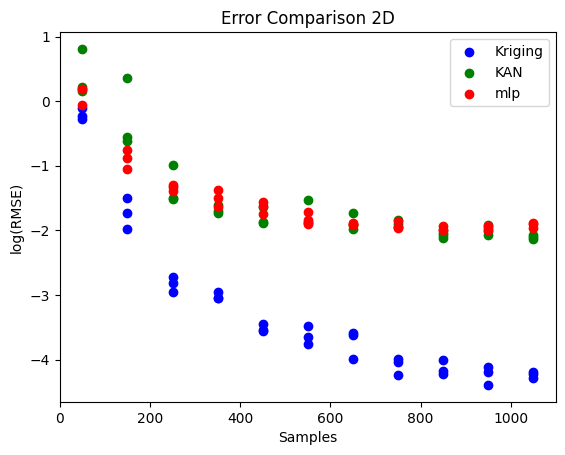

In [5]:
ax = plot_single_fidelity_data(
    points=kriging2D_points,
    output=kriging2D_error,
    label="Kriging",
    name="Error Comparison 2D",
    log_output=True,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan2D_points,
    output=kan2D_error,
    label="KAN",
    name="Error Comparison 2D",
    log_output=True,
    color="green",
    ax = ax,
)
ax = plot_single_fidelity_data(
    points=mlp2D_points,
    output=mlp2D_error,
    label="mlp",
    name="Error Comparison 2D",
    y_label="log(RMSE)",
    log_output=True,
    color="red",
    ax = ax,
)
plt.legend()
save_plot(ax, "Error Comparison 2D")
plt.show()

saved plots\SFComp\Train_Time_Comparison_2D.png


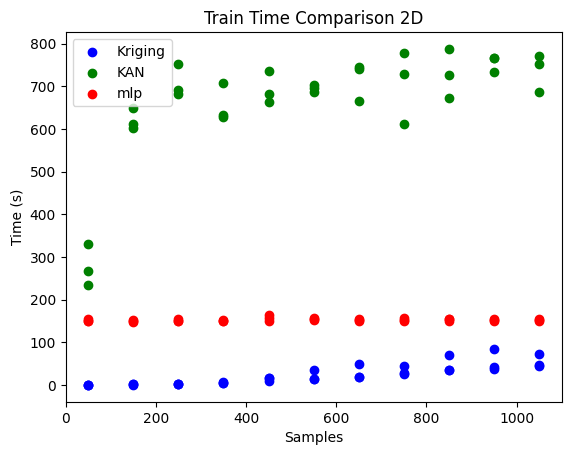

In [6]:
plot_name = "Train Time Comparison 2D"
log_output = False
y_label = "Time (s)"


ax = plot_single_fidelity_data(
    points=kriging2D_points,
    output=kriging2D_traintime,
    label="Kriging",
    name=plot_name,
    log_output=log_output,
    color="blue",
    y_label=y_label
)
ax = plot_single_fidelity_data(
    points=kan2D_points,
    output=kan2D_traintime,
    label="KAN",
    name=plot_name,
    log_output=log_output,
    y_label=y_label,
    color="green",
    ax = ax,
)
ax = plot_single_fidelity_data(
    points=mlp2D_points,
    output=mlp2D_traintime,
    label="mlp",
    name=plot_name,
    log_output=log_output,
    y_label=y_label,
    color="red",
    ax = ax,
)

plt.legend()
save_plot(ax, plot_name)
plt.show()

# 4D Comparison

In [7]:
kriging4D_points,kriging4D_error,kriging4D_traintime,kriging4D_evaltime = load_single_fidelity_csv_results('Comparisons/kriging_model_comparison_4D.csv')
kan4D_points,kan4D_error,kan4D_traintime,kan4D_evaltime = load_single_fidelity_csv_results('Comparisons/kan_model_comparison_4D.csv')
mlp4D_points,mlp4D_error,mlp4D_traintime,mlp4D_evaltime = load_single_fidelity_csv_results('Comparisons/nn_model_comparison_4d.csv')

saved plots\SFComp\Error_Comparison_4D.png


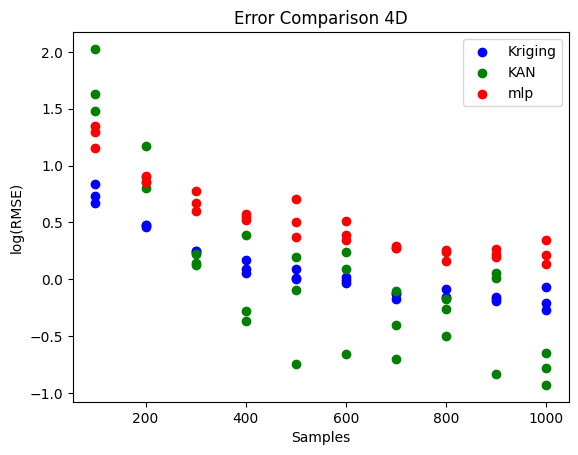

In [8]:
ax = plot_single_fidelity_data(
    points=kriging4D_points,
    output=kriging4D_error,
    label="Kriging",
    name="Error Comparison 4D",
    log_output=True,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan4D_points,
    output=kan4D_error,
    label="KAN",
    name="Error Comparison 4D",
    log_output=True,
    color="green",
    ax = ax,
)
ax = plot_single_fidelity_data(
    points=mlp4D_points,
    output=mlp4D_error,
    label="mlp",
    name="Error Comparison 4D",
    log_output=True,
    color="red",
    y_label="log(RMSE)",
    ax = ax,
)
plt.legend()
save_plot(ax, "Error Comparison 4D")
plt.show()

saved plots\SFComp\Train_Time_Comparison_4D.png


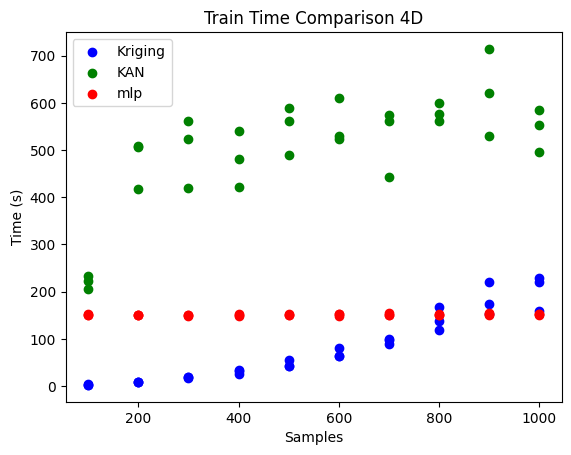

In [9]:
plot_name = "Train Time Comparison 4D"
log_output = False
y_label = "Time (s)"


ax = plot_single_fidelity_data(
    points=kriging4D_points,
    output=kriging4D_traintime,
    label="Kriging",
    name=plot_name,
    log_output=log_output,
    color="blue",
    y_label=y_label
)
ax = plot_single_fidelity_data(
    points=kan4D_points,
    output=kan4D_traintime,
    label="KAN",
    name=plot_name,
    log_output=log_output,
    y_label=y_label,
    color="green",
    ax = ax,
)
ax = plot_single_fidelity_data(
    points=mlp4D_points,
    output=mlp4D_traintime,
    label="mlp",
    name=plot_name,
    log_output=log_output,
    y_label=y_label,
    color="red",
    ax = ax,
)

plt.legend()
save_plot(ax, plot_name)
plt.show()

# 6D Comparison

In [10]:
kriging6D_points,kriging6D_error,kriging6D_traintime,kriging6D_evaltime = load_single_fidelity_csv_results('Comparisons/kriging_model_comparison_6D.csv')
kan6D_points,kan6D_error,kan6D_traintime,kan6D_evaltime = load_single_fidelity_csv_results('Comparisons/kan_model_comparison_6D.csv')
mlp6D_points,mlp6D_error,mlp6D_traintime,mlp6D_evaltime = load_single_fidelity_csv_results('Comparisons/nn_model_comparison_6D.csv')

saved plots\SFComp\Error_Comparison_6D.png


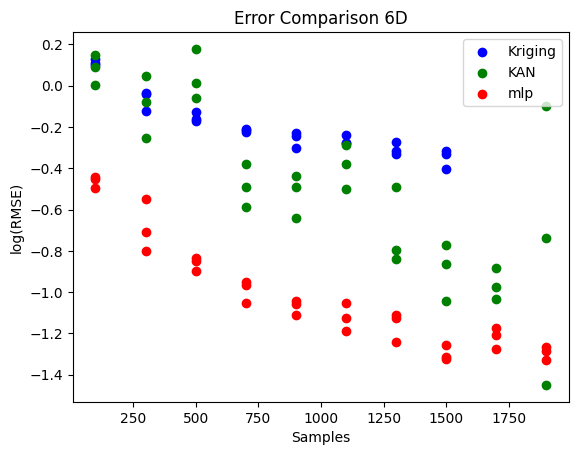

In [11]:
ax = plot_single_fidelity_data(
    points=kriging6D_points,
    output=kriging6D_error,
    label="Kriging",
    name="Error Comparison 6D",
    log_output=True,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan6D_points,
    output=kan6D_error,
    label="KAN",
    name="Error Comparison 6D",
    log_output=True,
    color="green",
    ax = ax,
)
ax = plot_single_fidelity_data(
    points=mlp6D_points,
    output=mlp6D_error,
    label="mlp",
    name="Error Comparison 6D",
    log_output=True,
    color="red",
    y_label="log(RMSE)",
    ax = ax,
)
plt.legend()
save_plot(ax, "Error Comparison 6D")
plt.show()

saved plots\SFComp\Train_Time_Comparison_6D.png


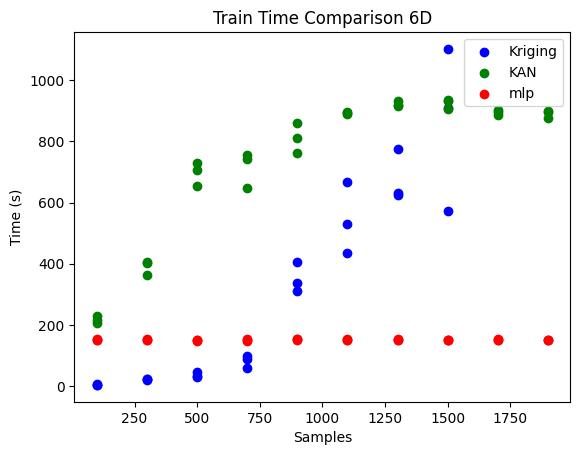

In [12]:
plot_name = "Train Time Comparison 6D"
log_output = False
y_label = "Time (s)"


ax = plot_single_fidelity_data(
    points=kriging6D_points,
    output=kriging6D_traintime,
    label="Kriging",
    name=plot_name,
    log_output=log_output,
    color="blue",
    y_label=y_label
)
ax = plot_single_fidelity_data(
    points=kan6D_points,
    output=kan6D_traintime,
    label="KAN",
    name=plot_name,
    log_output=log_output,
    y_label=y_label,
    color="green",
    ax = ax,
)
ax = plot_single_fidelity_data(
    points=mlp6D_points,
    output=mlp6D_traintime,
    label="mlp",
    name=plot_name,
    log_output=log_output,
    y_label=y_label,
    color="red",
    ax = ax,
)

plt.legend()
save_plot(ax, plot_name)
plt.show()

# 8D Comparison

In [13]:
kriging8D_points,kriging8D_error,kriging8D_traintime,kriging8D_evaltime = load_single_fidelity_csv_results('Comparisons/kriging_model_comparison_8D.csv')
kan8D_points,kan8D_error,kan8D_traintime,kan8D_evaltime = load_single_fidelity_csv_results('Comparisons/kan_model_comparison_8D.csv')
mlp8D_points,mlp8D_error,mlp8D_traintime,mlp8D_evaltime = load_single_fidelity_csv_results('Comparisons/nn_model_comparison_8D.csv')

saved plots\SFComp\Error_Comparison_8D.png


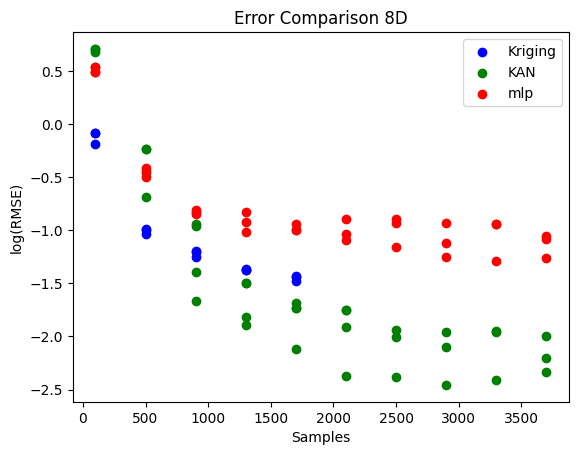

In [14]:
ax = plot_single_fidelity_data(
    points=kriging8D_points,
    output=kriging8D_error,
    label="Kriging",
    name="Error Comparison 8D",
    log_output=True,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan8D_points,
    output=kan8D_error,
    label="KAN",
    name="Error Comparison 8D",
    log_output=True,
    color="green",
    ax = ax,
)
ax = plot_single_fidelity_data(
    points=mlp8D_points,
    output=mlp8D_error,
    label="mlp",
    name="Error Comparison 8D",
    log_output=True,
    color="red",
    y_label="log(RMSE)",
    ax = ax,
)
plt.legend()
save_plot(ax, "Error Comparison 8D")
plt.show()

saved plots\SFComp\Train_Time_Comparison_8D.png


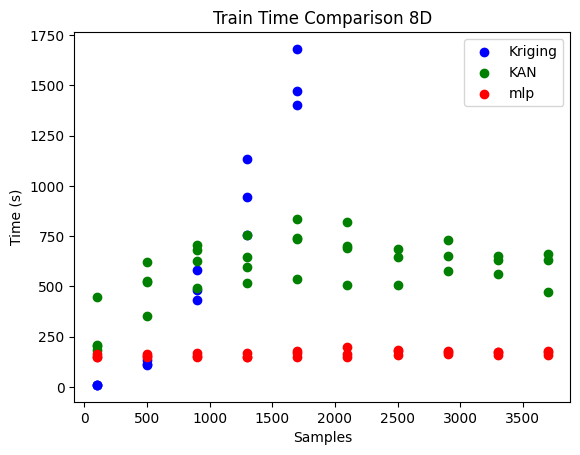

In [15]:
plot_name = "Train Time Comparison 8D"
log_output = False
y_label = "Time (s)"


ax = plot_single_fidelity_data(
    points=kriging8D_points,
    output=kriging8D_traintime,
    label="Kriging",
    name=plot_name,
    log_output=log_output,
    color="blue",
    y_label=y_label
)
ax = plot_single_fidelity_data(
    points=kan8D_points,
    output=kan8D_traintime,
    label="KAN",
    name=plot_name,
    log_output=log_output,
    y_label=y_label,
    color="green",
    ax = ax,
)
ax = plot_single_fidelity_data(
    points=mlp8D_points,
    output=mlp8D_traintime,
    label="mlp",
    name=plot_name,
    log_output=log_output,
    y_label=y_label,
    color="red",
    ax = ax,
)

plt.legend()
save_plot(ax, plot_name)
plt.show()

# 10D Comparison

In [16]:
kriging10D_points,kriging10D_error,kriging10D_traintime,kriging10D_evaltime = load_single_fidelity_csv_results('Comparisons/kriging_model_comparison_10D_mlp_ranges.csv')
kan10D_points,kan10D_error,kan10D_traintime,kan10D_evaltime = load_single_fidelity_csv_results('Comparisons/kan_model_comparison_10D.csv')
mlp10D_points,mlp10D_error,mlp10D_traintime,mlp10D_evaltime = load_single_fidelity_csv_results('Comparisons/nn_model_comparison_10D.csv')

saved plots\SFComp\Error_Comparison_10D.png


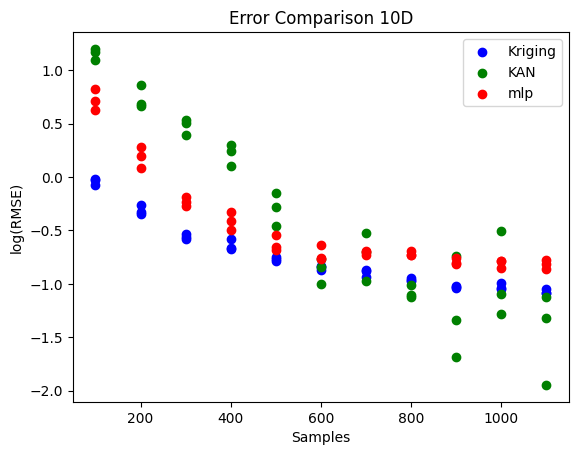

In [17]:
ax = plot_single_fidelity_data(
    points=kriging10D_points,
    output=kriging10D_error,
    label="Kriging",
    name="Error Comparison 10D",
    log_output=True,
    color="blue",
)
ax = plot_single_fidelity_data(
    points=kan10D_points,
    output=kan10D_error,
    label="KAN",
    name="Error Comparison 10D",
    log_output=True,
    color="green",
    ax = ax,
)
ax = plot_single_fidelity_data(
    points=mlp10D_points,
    output=mlp10D_error,
    label="mlp",
    name="Error Comparison 10D",
    log_output=True,
    color="red",
    y_label="log(RMSE)",
    ax = ax,
)
plt.legend()
save_plot(ax, "Error Comparison 10D")
plt.show()

[151.34031120000145, 149.00219079999806, 152.2255933000015, 150.07068159999835, 149.1480212000024, 151.90100410000014, 149.99617969999963, 151.9086838999974, 151.0980965000017, 151.12519789999715, 153.55723580000267, 150.17472909999924, 149.16344819999722, 152.53092910000123, 150.78433719999884, 150.75702190000084, 151.5316225000024, 151.06035800000245, 153.46313210000153, 152.91362949999893, 150.64418529999966, 152.48496050000176, 151.73520389999976, 149.86145469999974, 152.59225460000016, 149.66259399999763, 153.06047549999857, 151.60524670000086, 150.30871399999887, 153.88145390000136, 151.9427801999991, 150.9424194000021, 151.60391449999952]


saved plots\SFComp\Train_Time_Comparison_10D.png


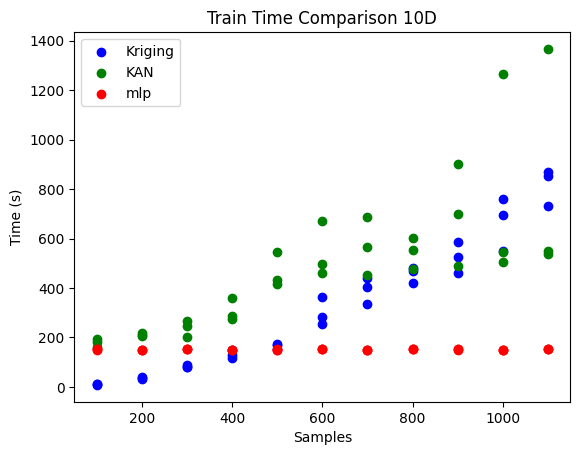

In [18]:
print(mlp10D_traintime)
plot_name = "Train Time Comparison 10D"
log_output = False
y_label = "Time (s)"


ax = plot_single_fidelity_data(
    points=kriging10D_points,
    output=kriging10D_traintime,
    label="Kriging",
    name=plot_name,
    log_output=log_output,
    color="blue",
    y_label=y_label
)
ax = plot_single_fidelity_data(
    points=kan10D_points,
    output=kan10D_traintime,
    label="KAN",
    name=plot_name,
    log_output=log_output,
    y_label=y_label,
    color="green",
    ax = ax,
)
ax = plot_single_fidelity_data(
    points=mlp10D_points,
    output=mlp10D_traintime,
    label="mlp",
    name=plot_name,
    log_output=log_output,
    y_label=y_label,
    color="red",
    ax = ax,
)

plt.legend()
save_plot(ax, plot_name)
plt.show()